# Duffell Gap

Comparison of `DustPy` (full coagulation) and `TriPoDPy` for a disk with a static planetary gap
(Duffell 2020 gap profile, planet at 5.2 au with mass ratio $q = 10^{-3}$, no gas evolution). The setup that was used to generate the figures in the JOSS paper.

Before running this notebook, run the `TriPoDPy` simulation from this folder:
* `python DuffellGap.py` (TriPoDPy, writes `data_duffle/`)

For the `DustPy` simulation you can either:
* use the sample snapshots from the `DustPy` simulation saved in `/Dustpy_setups/sample_data_gap` at [10<sup>3</sup>, 10<sup>4</sup>, 10<sup>5</sup> or 4*10<sup>5</sup>] Years
* or run `python Dustpy_setups/DuffellGap.py` (DustPy, writes `data_duffle_DP/`) this might take a day or to


In [9]:
from pathlib import Path
from types import SimpleNamespace

import numpy as np
import matplotlib.pyplot as plt
from matplotlib.colors import LogNorm
import dustpy as dp
from tripodpy.utils import get_q, get_size_distribution

au = dp.constants.au
yr = dp.constants.year

# figures are saved here
plot_dir = Path("plots/duffle")
plot_dir.mkdir(parents=True, exist_ok=True)

## Read data

In [10]:
dp_path = Path("./Dustpy_setups/sample_data_gap")     # DustPy output
tp_path = Path("data_duffle")  # TriPoDPy output

In [11]:
def read_dustpy(path):
    """Read a DustPy run and compute the quantities compared below."""
    reader = dp.hdf5writer()
    reader.datadir = str(path)
    data = reader.read.all()

    a = data.dust.a[0, 0]
    Sigma_d = data.dust.Sigma

    # a_max: particle size below which 99% of the dust mass is contained
    cum_mass = np.cumsum(Sigma_d, axis=-1)
    a_max = a[np.argmax(cum_mass / cum_mass[..., -1:] >= 0.99, axis=-1)]

    return SimpleNamespace(
        t=np.ravel(data.t),
        r=data.grid.r[0],
        a=a,
        Sigma_g=data.gas.Sigma,
        Sigma_d=Sigma_d,
        eps=data.dust.eps,
        a_1=(Sigma_d * a).sum(-1) / Sigma_d.sum(-1),  # mass-averaged particle size
        a_max=a_max,
    )


def read_tripodpy(path, a):
    """Read a TriPoDPy run and reconstruct its power-law size distribution
    on the particle size grid `a` (the DustPy grid)."""
    reader = dp.hdf5writer()
    reader.datadir = str(path)
    data = reader.read.all()

    Sigma_d = data.dust.Sigma  # (n_t, n_r, 2): small and large population
    a_max = data.dust.a[..., 4]

    # interfaces chosen such that the bin centres coincide with `a`
    A = np.mean(a[1:] / a[:-1])
    with np.errstate(divide="ignore", invalid="ignore"):
        q = get_q(Sigma_d, data.dust.s.min, a_max)
        _, _, Sigma_d_rec = get_size_distribution(
            Sigma_d.sum(-1),
            a_max,
            q=q,
            na=len(a),
            agrid_min=2 / (A + 1) * a[0],
            agrid_max=2 * A / (A + 1) * a[-1],
        )

    return SimpleNamespace(
        t=np.ravel(data.t),
        r=data.grid.r[0],
        a=a,
        Sigma_g=data.gas.Sigma,
        Sigma_d=Sigma_d_rec,
        eps=data.dust.eps,
        a_1=data.dust.a[..., 2],
        a_max=a_max,
    )

In [12]:
d_d = read_dustpy(dp_path)
d_t = read_tripodpy(tp_path, d_d.a)

for name, d in [("DustPy", d_d), ("TriPoDPy", d_t)]:
    print(f"{name:9s}: {len(d.t)} snapshots, t_end = {d.t[-1] / yr:.3g} yr")

# line styles for the comparison plots
styles = {"DustPy": dict(ls="-", c="k"), "TriPoDPy": dict(ls="--", c="C2")}

DustPy   : 4 snapshots, t_end = 4.08e+05 yr
TriPoDPy : 301 snapshots, t_end = 3e+06 yr


## Plots

### 2D distribution plot

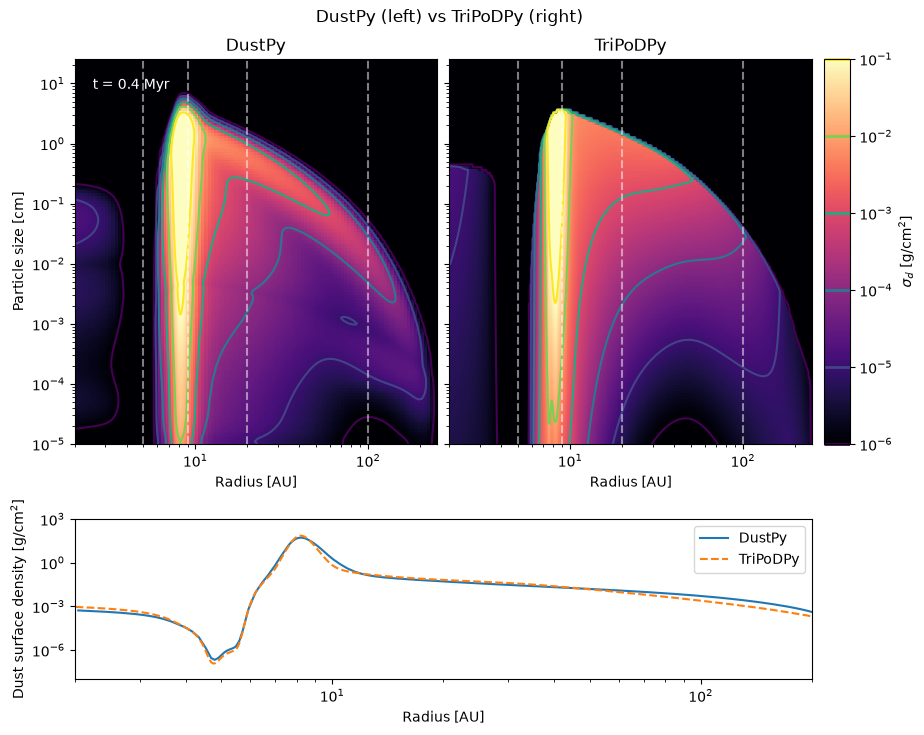

In [13]:
f, axs = plt.subplots(1, 3, figsize=(10, 5), gridspec_kw={'width_ratios': [1, 1, 0.07], 'wspace': 0.05})

vmin = 1e-6
vmax = 1e-1

time = 4e5*yr

for ax, d in zip(axs, [d_d, d_t]):

    it = np.abs(d.t - time).argmin()
    Sig_d_plot = d.Sigma_d[it, ...]
    Sig_d_plot = np.where(Sig_d_plot <= 0, vmin, Sig_d_plot)  # replace NaN with vmin

    pcm = ax.pcolormesh(d.r / au, d.a, Sig_d_plot.T, norm=LogNorm(vmin, vmax), cmap='magma')
    con = ax.contour(d.r / au, d.a, Sig_d_plot.T, np.geomspace(vmin, vmax, int(np.log10(vmax/vmin))+1), norm=LogNorm())
    ax.loglog()
    ax.set_xlabel('Radius [AU]')

axs[0].set_ylabel('Particle size [cm]')
for ax in axs[1:]:
    ax.set_yticklabels('')

for ax in axs[:-1]:
    for radius in [5, 9, 20, 100]:
        ax.axvline(radius, color='w', linestyle='--', alpha=0.5)
f.suptitle('DustPy (left) vs TriPoDPy (right)')
axs[0].set_title('DustPy')
axs[1].set_title('TriPoDPy')
axs[0].text(0.05, 0.95, "t = 0.4 Myr", transform=axs[0].transAxes, ha='left', va='top', color='w')
cb1 = f.colorbar(pcm, cax=axs[-1])
cb2 = f.colorbar(con, cax=axs[-1])
cb2.lines[0].set_linewidth(2)
cb2.set_label(r'$\sigma_d$ [g/cm$^2$]')

# total dust surface density below the two panels
pos0 = axs[0].get_position()
pos1 = axs[1].get_position()
left = pos0.x0
width = pos1.x1 - pos0.x0
bottom = pos0.y0 - 0.47
height = 0.32
ax_bot = f.add_axes([left, bottom, width, height])
for d, linestyle in zip([d_d, d_t], ['-', '--']):
    it = np.abs(d.t - time).argmin()
    ax_bot.loglog(d.r / au, d.Sigma_d[it, ...].sum(-1), linestyle=linestyle)

ax_bot.legend(['DustPy', 'TriPoDPy'])
ax_bot.set_ylim(1e-8, 1e3)
ax_bot.set_xlim(2, 200)
ax_bot.set_xlabel('Radius [AU]')
ax_bot.set_ylabel('Dust surface density [g/cm$^2$]');

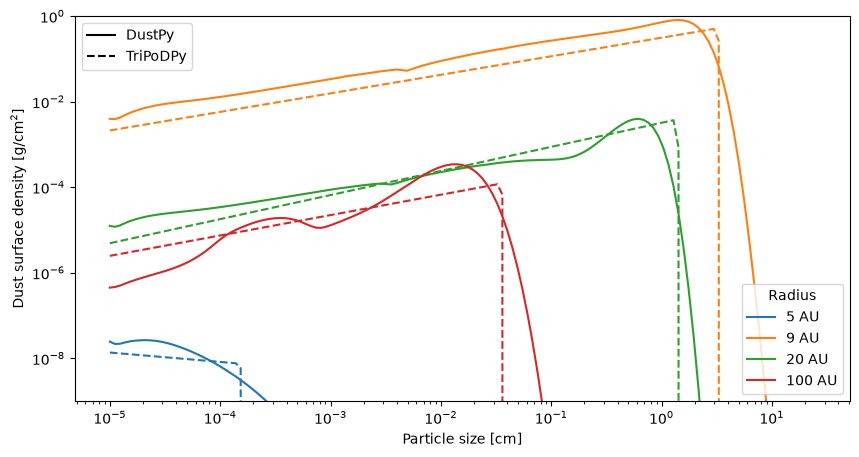

In [14]:
f, ax = plt.subplots(1, 1, figsize=(10, 5))

time = 4e5*yr
radii_au = [5, 9, 20, 100]

for r_ind, r_au in enumerate(radii_au):
    for d, linestyle in zip([d_d, d_t], ['-', '--']):
        it = np.abs(d.t - time).argmin()
        ir = np.abs(d.r/au - r_au).argmin()
        label = f'{r_au} AU' if d is d_d else None
        ax.plot(d.a, d.Sigma_d[it, ir, :], label=label, linestyle=linestyle, color=f'C{r_ind % 10}')

ax.set_xscale('log')
ax.set_yscale('log')
ax.legend(title='Radius', loc='lower right')
ax.set_ylim(1e-9, 1e0)
ax.set_ylabel('Dust surface density [g/cm$^2$]')
ax.set_xlabel('Particle size [cm]')
ax2 = ax.twinx()
ax2.plot([], [], 'k-', label='DustPy')
ax2.plot([], [], 'k--', label='TriPoDPy')
ax2.legend(loc='upper left')
ax2.set_axis_off()
plt.savefig(plot_dir / "size_dist_radius_compare")